In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Figures for Nir — the batch-2 set on the synthetic cars

The three figures of [figs4nir2.ipynb](figs4nir2.ipynb), redone on `data/synthetic_cars/` (120 cars, 6 features,
3 models, 28 contracts). Same look. What each one became:

| figs4nir2 (laptops) | here (cars) |
|---|---|
| **A** persona effect on the feature weights (student, video editor) | **A** effect of a track's full contract on the feature weights. A track (luxury, economy, family, work) is the cars' "kind of user". There are no persona runs for cars. |
| **B** contract paths: rank of the user's laptop after 0-3 requests, all 6 orders | **B** contract paths: rank of the track's best target car after 0-4 requests. Only ONE order per track was collected, so the pale lines are the other possible FIRST requests. |
| **C** coherence / sharpness / agreement across simple domains, base vs tuned | **C** the same three numbers across kinds of request (none, company, color, ...), and no contract vs one request. Cars have one domain and no base models. |

Rank of a car = 1 + the number of cars that beat it head to head (position-corrected margin). Every pair with a
target car was scored under every contract, so this rank is exact at every step, also under the compound
contracts where the other pairs are only a sample.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from src.bt import FeatureBT

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/figs4nir_cars"
os.makedirs(FIGDIR, exist_ok=True)

FEATS = ["company", "color", "fuel", "transmission", "ownership", "horsepower"]
LEVELS = {
    "company": ["Honda", "Toyota", "Ford", "BMW", "Audi", "Mercedes"],
    "color": ["white", "black", "silver", "red", "blue", "grey"],
    "fuel": ["petrol", "diesel"],
    "transmission": ["manual", "automatic"],
    "ownership": ["private first owner", "private second owner", "private third owner", "ex-lease", "ex-rental"],
    "horsepower": ["100 hp", "150 hp", "200 hp"],
}
SHORT = {"private first owner": "1st owner", "private second owner": "2nd owner", "private third owner": "3rd owner"}
FEATURE_COLOR = {"company": "#6aa83f", "color": "#c75f8b", "fuel": "#d9783f", "transmission": "#8a6fc9",
                 "ownership": "#3aa6a0", "horsepower": "#4c8fd4"}        # company / horsepower = brand / ram of figs4nir2
TRACKS = {                                                                # a track = a kind of user, requests in order
    "luxury": [("transmission", "automatic"), ("company", "BMW"), ("horsepower", "200 hp"), ("color", "black")],
    "economy": [("fuel", "petrol"), ("transmission", "manual"), ("horsepower", "100 hp"), ("company", "Honda")],
    "family": [("transmission", "automatic"), ("ownership", "private first owner"), ("company", "Toyota"),
               ("color", "white")],
    "work": [("fuel", "diesel"), ("horsepower", "150 hp"), ("company", "Ford"), ("ownership", "ex-lease")],
}
TRACK_COLOR = {"luxury": "#3b6fc4", "economy": "#df7a3e", "family": "#2e9a68", "work": "#8e63c7"}
MODELS = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]
ITEMS = pd.read_csv("data/synthetic_cars/design/items.csv")
N = len(ITEMS)
TARGETS = {t: ITEMS.index[(ITEMS.part == "target") & (ITEMS.track == t)].tolist() for t in TRACKS}   # 3 cars per track
COLS = [f"{p}_{f}" for p in "ab" for f in FEATS] + ["score_a", "score_b"]

RUNS = {}      # (model, frozenset of (feature, level)) -> the rows, and D[i, j] > 0: car i is preferred to car j
for r in sorted(os.listdir("data/synthetic_cars")):
    cf, sc = f"data/synthetic_cars/{r}/config.json", f"data/synthetic_cars/{r}/scores.csv"
    if not (os.path.isfile(cf) and os.path.isfile(sc)):
        continue                                         # log-only folders of the failed first launch
    c = json.load(open(cf))
    d = pd.read_csv(sc)
    if len(d) != c["n_rows"]:
        continue
    key = ((c["model_family"], str(c["model_size"])), frozenset(c["constraints"].items()))
    assert key not in RUNS, f"two complete runs for {key}"
    M = np.full((N, N), np.nan)
    M[d.a_id.values - 1, d.b_id.values - 1] = (d.score_a - d.score_b).values
    RUNS[key] = {"d": d, "D": (M - M.T) / 2}
print(len(RUNS), "runs")


def name(m):
    return f"{m[0]}-{m[1]}B"


def run(m, con=()):
    return RUNS[(m, frozenset(con))]

84 runs


## A — effect of a track's full contract on the feature weights

Bars = weight of each level under the track's 4-request contract minus its weight with no contract (BT-feat,
`src/bt.py`). A dark outline marks the four levels that were asked for.

**Both fits use the 500 shared pairs only** (1,000 rows each; corrected 2026-11-15). A compound run also holds
every pair with one of the track's 3 target cars, about 40% of its rows. The target cars win those pairs because
they meet the contract, and an additive fit on all rows then gives the credit to everything the target cars have
in common or happen to have - for example their colour. The first version of this figure had that bias.
A smaller form of it remains: few cars meet a compound contract, so a bar of a feature that was NOT asked for
can still reflect which cars happen to meet the contract.

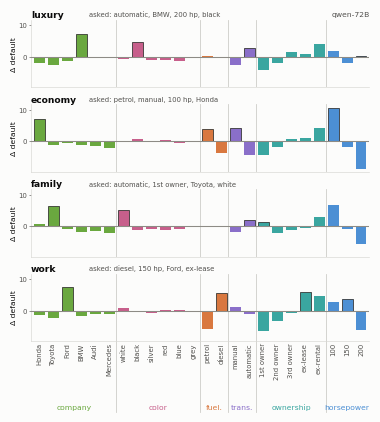

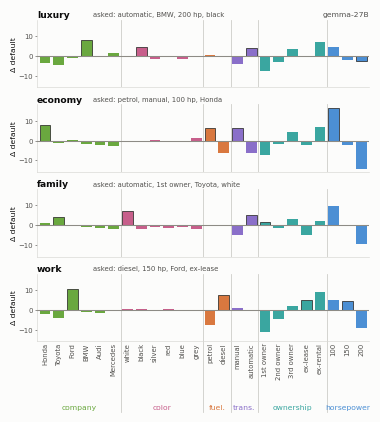

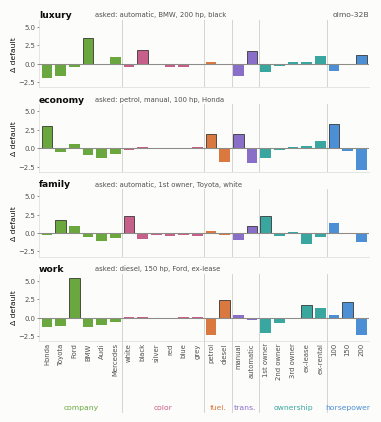

In [3]:
LV = [(f, l) for f in FEATS for l in LEVELS[f]]
LABEL = {l: SHORT.get(l, l).replace(" hp", "") for _, l in LV}


_sh = pd.read_csv("data/synthetic_cars/design/compound_pairs.csv").values
SHARED = set(map(tuple, _sh)) | set(map(tuple, _sh[:, ::-1]))          # the 500 shared pairs, both orders


def weights(m, con=()):
    """BT-feat weights on the 500 shared pairs only (1,000 rows)."""
    d = run(m, con)["d"]
    return FeatureBT(r2_warn=None).fit(d[[k in SHARED for k in zip(d.a_id, d.b_id)]][COLS]).weights_


DELTA = {}
for m in MODELS:
    w0 = weights(m)
    for t in TRACKS:
        w1 = weights(m, TRACKS[t])
        DELTA[(m, t)] = pd.Series({(f, l): w1[f][l] - w0[f][l] for f, l in LV})


def fig_a(m):
    lo = min(DELTA[(m, t)].min() for t in TRACKS) * 1.1          # one y scale for the four panels of a model
    hi = max(DELTA[(m, t)].max() for t in TRACKS) * 1.1
    fig, axes = plt.subplots(len(TRACKS), 1, figsize=(3.3, 3.5), sharex=True, sharey=True)
    x = np.arange(len(LV))
    for ax, t in zip(axes, TRACKS):
        asked = set(TRACKS[t])
        ax.bar(x, DELTA[(m, t)].values, 0.78, color=[FEATURE_COLOR[f] for f, _ in LV], zorder=2,
               edgecolor=["#2b2b29" if fl in asked else "none" for fl in LV], linewidth=0.5)
        ax.axhline(0, color="#8d8b85", lw=0.7, zorder=3)
        ax.set_title(t, loc="left", fontsize=6, fontweight="bold", pad=1.5)
        ax.text(0.17, 1.03, "asked: " + ", ".join(LABEL[l] + (" hp" if f == "horsepower" else "") for f, l in TRACKS[t]),
                transform=ax.transAxes, ha="left", va="bottom", fontsize=4.5, color=INK_MUTED)
        ax.set_ylabel("Δ default", fontsize=5, labelpad=1)
        ax.set_ylim(lo, hi)
        ax.tick_params(axis="y", labelsize=4.5, length=1.5, width=0.4, pad=1, colors=INK_MUTED)
        ax.tick_params(axis="x", length=0, pad=1)
        ax.spines["left"].set_linewidth(0.4)
        ax.spines["bottom"].set_linewidth(0.4)
        ax.set_xlim(-0.6, len(LV) - 0.4)
    axes[0].text(1, 1.03, name(m), transform=axes[0].transAxes, ha="right", va="bottom", fontsize=5, color=INK_MUTED)
    axes[-1].set_xticks(x, [LABEL[l] for _, l in LV], rotation=90, fontsize=4.5, color=INK_MUTED)
    fig.tight_layout(h_pad=0.5, pad=0.15, rect=(0, 0.03, 1, 1))
    edges = np.cumsum([len(LEVELS[f]) for f in FEATS])
    for k in edges[:-1]:
        for ax in axes:
            ax.axvline(k - 0.5, color="#c9c8c3", lw=0.5, zorder=1)
        axes[-1].plot([k - 0.5, k - 0.5], [0, -1.05], transform=axes[-1].get_xaxis_transform(), color="#c9c8c3",
                      lw=0.5, clip_on=False)
    for f, b in zip(FEATS, edges):
        a = b - len(LEVELS[f])
        axes[-1].text((a + b - 1) / 2, -0.98, f if len(LEVELS[f]) > 2 else f[:5] + ".", ha="center", va="center",
                      transform=axes[-1].get_xaxis_transform(), fontsize=5, color=FEATURE_COLOR[f])
    fig.savefig(os.path.join(FIGDIR, f"A_contract_delta_{name(m)}.png"), facecolor=SURFACE, dpi=400)
    fig.savefig(os.path.join(FIGDIR, f"A_contract_delta_{name(m)}.pdf"), facecolor=SURFACE)
    plt.show()


for m in MODELS:
    fig_a(m)

## B — contract paths

x = how many of the track's requests were given (0 = none, 4 = all four). y = rank of the track's best target
car among the 120 (1 = on top). The bold line follows the track's own order of requests. The pale stubs are the
other three requests of the track, each given alone as the first request.

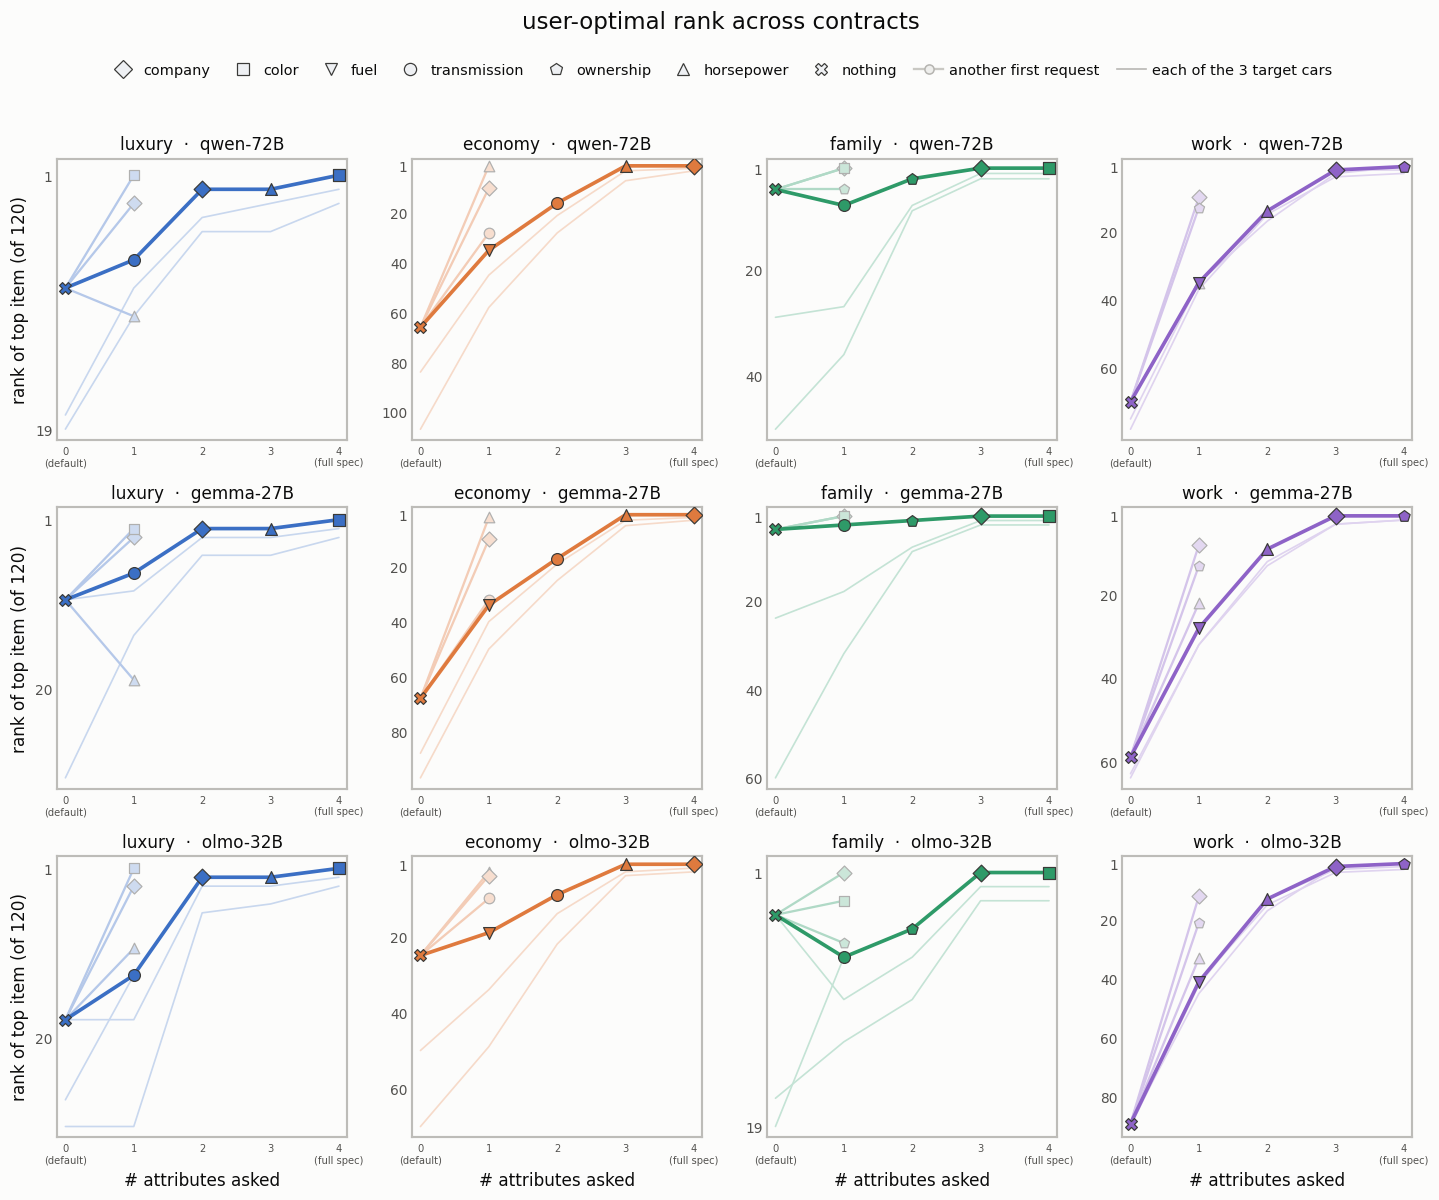

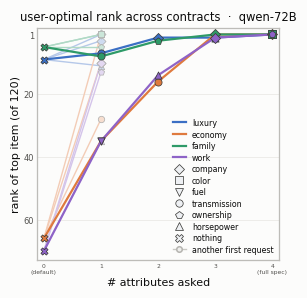

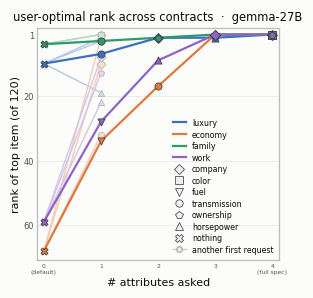

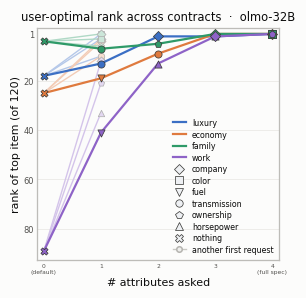

,model,track,k=0,k=1,k=2,k=3,k=4
0,qwen-72B,luxury,9,7,2,2,1
1,qwen-72B,economy,66,35,16,1,1
2,qwen-72B,family,5,8,3,1,1
3,qwen-72B,work,70,35,14,2,1
4,gemma-27B,luxury,10,7,2,2,1
5,gemma-27B,economy,68,34,17,1,1
6,gemma-27B,family,4,3,2,1,1
7,gemma-27B,work,59,28,9,1,1
8,olmo-32B,luxury,18,13,2,2,1
9,olmo-32B,economy,25,19,9,1,1


In [4]:
MARK = {"company": "D", "color": "s", "fuel": "v", "transmission": "o", "ownership": "p", "horsepower": "^"}
EMPTY = "X"                                                   # k = 0: the empty contract
FRAME_COL = "#bdbcb8"
K = 4


def rank(m, con, i):
    """1 + the number of cars that beat car i head to head under contract `con`."""
    v = np.delete(run(m, con)["D"][i], i)
    assert np.isfinite(v).all(), "a pair with a target car was not scored"
    return 1 + int((v < 0).sum())


def track_ranks(m, t):
    """Rank of each of the 3 target cars after the first k requests of the track: array 3 x 5."""
    return np.array([[rank(m, TRACKS[t][:k], i) for k in range(K + 1)] for i in TARGETS[t]])


def first_requests(m, t):
    """Best target's rank when ONE request of the track is given alone: {(feature, level): rank}."""
    return {fv: min(rank(m, [fv], i) for i in TARGETS[t]) for fv in TRACKS[t]}


def pale(color, t=0.62):
    c, w = np.array(to_rgb(color)), np.ones(3)
    return tuple(c + (w - c) * t)


def panel(ax, m, tracks, each_target=False, ymax=None, sc=1.0):
    """One axis: the tracks in `tracks`, each in its colour. sc scales every size for a smaller figure."""
    data = [(t, track_ranks(m, t), first_requests(m, t)) for t in tracks]
    ymax = ymax or max(max(P.max() if each_target else P.min(0).max(), max(fr.values())) for _, P, fr in data)
    for t, P, fr in data:                                          # all pale marks first ...
        col, best = TRACK_COLOR[t], P.min(0)
        if each_target:
            for y in P:
                ax.plot(range(K + 1), y, color=pale(col, 0.72), lw=1.1 * sc, zorder=1.5, solid_capstyle="round")
        for fv in TRACKS[t][1:]:
            ax.plot([0, 1], [best[0], fr[fv]], color=pale(col), lw=1.5 * sc, zorder=2, solid_capstyle="round")
            ax.scatter(1, fr[fv], marker=MARK[fv[0]], s=48 * sc ** 2, zorder=3, color=pale(col, 0.75),
                       edgecolor=pale("#3a3a38", 0.6), lw=0.8 * sc)
    for t, P, fr in data:                                          # ... then the track's own path on top
        col, best = TRACK_COLOR[t], P.min(0)
        ax.plot(range(K + 1), best, color=col, lw=2.4 * sc, zorder=4, solid_capstyle="round")
        for k in range(1, K + 1):
            ax.scatter(k, best[k], marker=MARK[TRACKS[t][k - 1][0]], s=60 * sc ** 2, zorder=6, color=col,
                       edgecolor="#3a3a38", lw=0.8 * sc)
        ax.scatter(0, best[0], marker=EMPTY, s=60 * sc ** 2, zorder=6, color=col, edgecolor="#3a3a38", lw=0.8 * sc)
    ax.set_xlim(-0.12, K + 0.12)
    ax.set_ylim(ymax + 0.04 * ymax, 0.2 - 0.02 * ymax)
    ax.set_yticks([1, int(ymax)] if ymax < 30 else [1] + list(range(20, int(ymax) + 1, 20)))
    ax.set_xticks(range(K + 1), ["0\n(default)", "1", "2", "3", "4\n(full spec)"], fontsize=6.5 * sc, color=INK_MUTED)
    ax.tick_params(axis="x", length=0, pad=4 * sc)
    ax.tick_params(axis="y", length=0, labelsize=9 * sc, pad=3 * sc)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(FRAME_COL); sp.set_linewidth(1.4 * sc)
    return ymax


def handles(tracks, sc=1.0, extra=True):
    h = [plt.Line2D([], [], color=TRACK_COLOR[t], lw=2.4 * sc, label=t) for t in tracks]
    h += [plt.Line2D([], [], marker=MARK[f], ls="", ms=8 * sc, color="#eef0f3", markeredgecolor="#3a3a38",
                     mew=0.8 * sc, label=f) for f in FEATS]
    h.append(plt.Line2D([], [], marker=EMPTY, ls="", ms=8 * sc, color="#eef0f3", markeredgecolor="#3a3a38",
                        mew=0.8 * sc, label="nothing"))
    if extra:
        h.append(plt.Line2D([], [], color="#c9c8c3", lw=1.5 * sc, marker="o", ms=6 * sc, markerfacecolor="#eeeeec",
                            markeredgecolor="#b5b4b0", label="another first request"))
    return h


def draw_grid(fname=None):
    """Rows = models, columns = tracks. Thin lines = each of the 3 target cars; bold = the best of them."""
    fig, axes = plt.subplots(len(MODELS), len(TRACKS), figsize=(3.3 * len(TRACKS), 3.5 * len(MODELS)), squeeze=False)
    for i, m in enumerate(MODELS):
        for j, t in enumerate(TRACKS):
            panel(axes[i, j], m, [t], each_target=True)
            axes[i, j].set_title(f"{t}  ·  {name(m)}", fontsize=11, pad=6)
    for ax in axes[-1]:
        ax.set_xlabel("# attributes asked", fontsize=11)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"rank of top item (of {N})", fontsize=11)
    h = handles([], extra=True)
    h.append(plt.Line2D([], [], color="#b9b8b4", lw=1.1, label="each of the 3 target cars"))
    fig.legend(handles=h, loc="upper center", ncol=len(h), frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 1.0),
               columnspacing=1.2, handletextpad=0.4)
    fig.suptitle("user-optimal rank across contracts", fontsize=15, y=1.035)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    if fname:
        fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()


def draw_final(m, tracks=list(TRACKS), fname=None, size=2.6):
    """One axis in the reference design: the four tracks of one model, legend inside.
    size = figure width = height in inches; every size inside scales with it (designed at 4.3 in)."""
    sc = size / 4.3
    fig, ax = plt.subplots(figsize=(size, size))
    ymax = panel(ax, m, tracks, sc=sc)
    for y in range(20, int(ymax) + 1, 20):                           # light guide lines every 20 ranks
        ax.axhline(y, color="#e8e7e3", lw=0.8 * sc, zorder=0)
    ax.set_xlabel("# attributes asked", fontsize=12 * sc, labelpad=3 * sc)
    ax.set_ylabel(f"rank of top item (of {N})", fontsize=12 * sc, labelpad=3 * sc)
    ax.set_title(f"user-optimal rank across contracts  ·  {name(m)}", fontsize=12.5 * sc, pad=8 * sc)
    ax.legend(handles=handles(tracks, sc), frameon=False, fontsize=8.6 * sc, loc="lower right", handlelength=1.6,
              labelspacing=0.32, borderaxespad=0.3)
    fig.tight_layout(pad=0.3)
    if fname:
        fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE, dpi=400)
        fig.savefig(os.path.join(FIGDIR, fname + ".pdf"), facecolor=SURFACE)
    plt.show()


draw_grid("B_contract_paths.png")
for m in MODELS:
    draw_final(m, fname=f"B_contract_paths_final_{name(m)}")

# the numbers behind the bold lines and the stubs
PATH_T = pd.DataFrame([{"model": name(m), "track": t, **{f"k={k}": int(track_ranks(m, t).min(0)[k]) for k in range(K + 1)},
                        **{f"alone: {v}": r for (f, v), r in first_requests(m, t).items()}}
                       for m in MODELS for t in TRACKS])
PATH_T.to_csv(os.path.join(FIGDIR, "B_contract_paths.csv"), index=False)
PATH_T[["model", "track"] + [f"k={k}" for k in range(K + 1)]]

## C — coherence, sharpness, agreement across kinds of request

The three numbers of figs4nir2-C, same definitions, on the 16 runs that hold every pair (no contract + the 15
single requests):

- **coherence** — Spearman between the Bradley-Terry scores and the Borda scores of the 120 cars (mean of the 3 models)
- **sharpness** — mean of tanh(|D̄| / 2) over the pairs (mean of the 3 models)
- **agreement** — Kendall's W of the 3 models' rankings of the 120 cars

A group on the left = the single requests on that feature (company 4, horsepower 3, the others 2 each).
The BT fit is the model of `src/pref_models.fit_BT_soft`, written with arrays (the original loops in Python and
needs hours for 120 items); the check below compares the two on 12 cars.

check vs fit_BT_soft on 12 cars: max |difference| = 5.5e-05


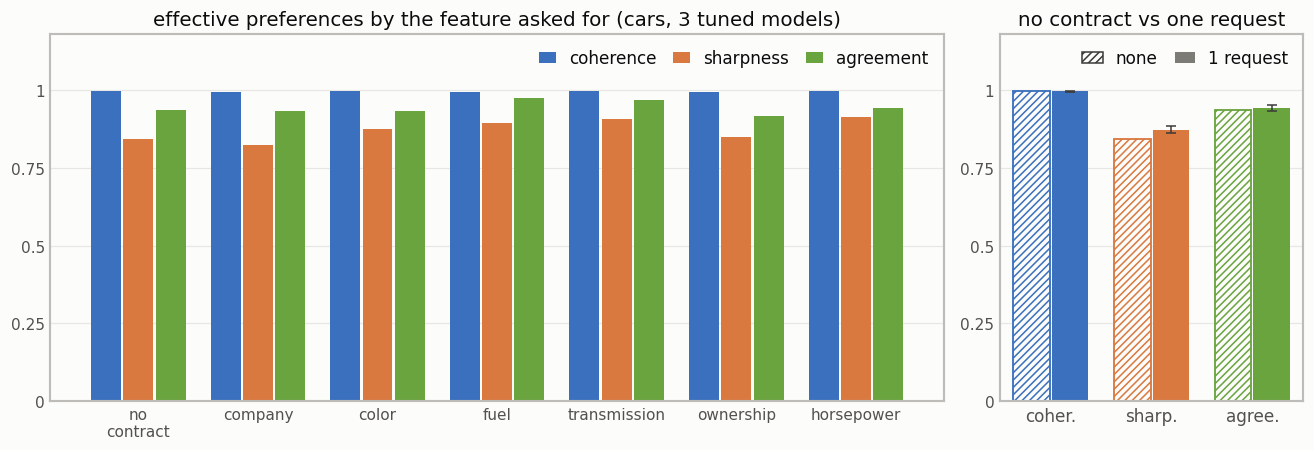

,coherence,sharpness,agreement
group,,,
none,0.998,0.844,0.937
company,0.995,0.824,0.933
color,0.997,0.875,0.934
fuel,0.994,0.894,0.976
transmission,0.996,0.908,0.968
ownership,0.995,0.849,0.916
horsepower,0.997,0.914,0.943


In [5]:
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import spearmanr, rankdata
from src.pref_models import fit_BT_soft

MCOL = {"coherence": "#3a70bd", "sharpness": "#d9783f", "agreement": "#6aa43f"}
SINGLES = list(dict.fromkeys(fv for t in TRACKS.values() for fv in t))       # the 15 single requests
GROUPS = ["none"] + FEATS


def bt_soft(d, n=N):
    """Bradley-Terry by cross-entropy on soft wins: the model of src.pref_models.fit_BT_soft, vectorised."""
    W = np.zeros((n, n))
    p = expit((d.score_a - d.score_b).values)
    np.add.at(W, (d.a_id.values - 1, d.b_id.values - 1), p)
    np.add.at(W, (d.b_id.values - 1, d.a_id.values - 1), 1 - p)

    def nll(b):
        z = b[:, None] - b[None, :]
        return -(W * (z - np.logaddexp(z, 0))).sum(), -((W * expit(-z)).sum(1) - (W * expit(-z)).sum(0))

    b = minimize(nll, np.zeros(n), jac=True, method="BFGS").x
    return b - b.mean()


# check on 12 cars: the vectorised fit gives the scores of the original function
_d = run(MODELS[0])["d"]
_d = _d[(_d.a_id <= 12) & (_d.b_id <= 12)]
_old = fit_BT_soft(_d.rename(columns={"a_id": "item_a", "b_id": "item_b"}), list(range(1, 13)))[0].BT_Score.values
print("check vs fit_BT_soft on 12 cars: max |difference| =", f"{np.abs(bt_soft(_d, 12) - _old).max():.1e}")


def kendall_w(R):
    m, n = R.shape
    return 12 * ((R.sum(0) - m * (n + 1) / 2) ** 2).sum() / (m ** 2 * (n ** 3 - n))


iu = np.triu_indices(N, 1)
rows, BORDA_C = [], {}
for con in [()] + [(fv,) for fv in SINGLES]:
    for m in MODELS:
        r = run(m, con)
        borda = np.nanmean(r["D"], axis=1)
        BORDA_C[(m, con)] = borda
        rows.append({"contract": con[0][1] if con else "none", "group": con[0][0] if con else "none", "model": name(m),
                     "coherence": spearmanr(bt_soft(r["d"]), borda)[0],
                     "sharpness": np.tanh(np.abs(r["D"][iu]) / 2).mean()})
CT = pd.DataFrame(rows)
PER = CT.groupby(["group", "contract"], sort=False)[["coherence", "sharpness"]].mean().reset_index()
PER["agreement"] = [kendall_w(np.array([rankdata(-BORDA_C[(m, con)]) for m in MODELS]))
                    for con in [()] + [(fv,) for fv in SINGLES]]
SUM = PER.groupby("group")[list(MCOL)].mean().loc[GROUPS]
PER.to_csv(os.path.join(FIGDIR, "C_contract_summary.csv"), index=False)


def frame_c(ax):
    ax.set_ylim(0, 1.18)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
    ax.grid(True, axis="y", color="#e8e7e3", lw=0.8, zorder=0)
    ax.tick_params(length=0, labelsize=10)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#bdbcb8"); sp.set_linewidth(1.4)


def fig_c(fname="C_contract_summary"):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(4 + 1.15 * len(GROUPS), 4.2),
                                 gridspec_kw={"width_ratios": [0.42 * len(GROUPS), 1]})
    x = np.arange(len(GROUPS))
    for j, lab in enumerate(MCOL):
        a1.bar(x + (j - 1) * 0.27, SUM[lab].clip(lower=0), 0.25, color=MCOL[lab], label=lab, zorder=2)
    frame_c(a1)
    a1.set_xticks(x, ["no\ncontract"] + FEATS, fontsize=10)
    a1.legend(frameon=False, ncol=3, loc="upper right", fontsize=11, handlelength=1, columnspacing=1)
    a1.set_title("effective preferences by the feature asked for (cars, 3 tuned models)", fontsize=13)
    one = PER[PER.group != "none"]
    for i, lab in enumerate(MCOL):
        a2.bar(i - 0.19, PER[PER.group == "none"][lab].iloc[0], 0.36, zorder=2, color=SURFACE, edgecolor=MCOL[lab],
               hatch="/////", lw=1.2)
        a2.bar(i + 0.19, one[lab].mean(), 0.36, yerr=one[lab].std(ddof=1) / np.sqrt(len(one)), capsize=3,
               error_kw={"lw": 1, "ecolor": "#3a3a38"}, zorder=2, color=MCOL[lab])
    frame_c(a2)
    a2.set_xticks(range(3), ["coher.", "sharp.", "agree."], fontsize=11)
    a2.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor="#3a3a38", hatch="/////", label="none"),
                       plt.Rectangle((0, 0), 1, 1, facecolor="#7d7b76", label="1 request")],
              frameon=False, fontsize=11, loc="upper right", ncol=2, handlelength=1.2, columnspacing=1)
    a2.set_title("no contract vs one request", fontsize=13)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE)
    fig.savefig(os.path.join(FIGDIR, fname + ".pdf"), facecolor=SURFACE)
    plt.show()


fig_c()
SUM.round(3)